# 02 — Représentation et modèles de référence

**Objectif** : construire la représentation des bugs et établir les performances de référence que le JEM devra égaler ou dépasser.

**Principaux résultats**

- Chaque bug devient un vecteur dense de **417 dimensions** (TF-IDF titre et description → SVD 256, + one-hot des catégories), continu comme l'exige l'échantillonnage de Langevin du JEM.
- Le signal lexical reflète surtout **les équipes et le calendrier des versions** (expériences Nimbus, onboarding pour P1 ; réseau pour P2), plus que la gravité.
- Sur le test 2026 : « toujours P3 » 39 % d'accuracy, régression logistique **0,459**, MLP **0,469** (F1 macro ≈ 0,40). Le plafond vient des données, pas du réglage.
- Le MLP est bien calibré (ECE 0,045) mais **plus confiant sur les bugs de bots que sur les bugs humains** : sa confiance ne permet pas de repérer un bug atypique (AUROC 0,35).

Tous les entraînements sont suivis dans **MLflow** (`sqlite:///mlflow.db`) : paramètres, courbes par époque, métriques de test et modèle sérialisé.

In [1]:
import logging
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # chemins relatifs à la racine du projet (data/, mlflow.db)

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from jem_prioriser.plotstyle import CLASS_COLORS, HUMAN_BOT_COLORS, MODEL_COLORS, SERIES, use_style

logging.getLogger("mlflow").setLevel(logging.ERROR)
use_style()
pd.set_option("display.max_colwidth", 90)

## 1. Représentation

| Étape | Choix | Raison |
|---|---|---|
| TF-IDF titre et description | vocabulaires séparés, uni- et bigrammes, `sublinear_tf`, `min_df` 3/5 | un terme pèse plus dans le titre ; les journaux d'erreur ne doivent pas dominer |
| One-hot produit, composant, type, OS | catégories de moins de 20 bugs regroupées | robustesse aux composants rares ou nouveaux |
| SVD tronquée (LSA) | 256 composantes | espace dense et continu pour le JEM |
| Standardisation | moyenne 0, écart-type 1 | optimisation ; initialisation N(0, 1) des chaînes de Langevin |

Tout est appris sur la période d'entraînement uniquement (`jem_prioriser.features.BugFeaturizer`). La matrice de projection est stockée en `float32` et la liste des termes écartés par le TF-IDF est supprimée, ce qui ramène le modèle sérialisé de 91 Mo à 47 Mo.

In [2]:
from jem_prioriser.cleaning import CLASSES
from jem_prioriser.train import prepare_data

data = prepare_data()
f = data.featurizer
y_test = data.test["y"].to_numpy()
print(f"vocabulaires : titre {len(f.tfidf_summary.vocabulary_)} termes, description {len(f.tfidf_description.vocabulary_)} termes")
print(f"représentation creuse : {f.transform_sparse(data.val).shape[1]} colonnes | dense : {data.x_train.shape[1]} dimensions")
print(f"variance du TF-IDF conservée par la SVD : {f.explained_variance():.1%}")
print(f"train / validation / test : {len(data.train)} / {len(data.val)} / {len(data.test)}")

vocabulaires : titre 13234 termes, description 30000 termes


représentation creuse : 43395 colonnes | dense : 417 dimensions
variance du TF-IDF conservée par la SVD : 19.9%
train / validation / test : 16345 / 2649 / 2215


## 2. Signal lexical par classe

*Lift* des termes du titre : poids TF-IDF moyen dans la classe rapporté au poids moyen global (termes présents dans au moins 40 bugs).

In [3]:
X = f.tfidf_summary.transform(data.train.summary)
terms = f.tfidf_summary.get_feature_names_out()
doc_freq = np.asarray((X > 0).sum(0)).ravel()
overall = np.asarray(X.mean(0)).ravel()
top = {}
for k, c in enumerate(CLASSES):
    in_class = np.asarray(X[(data.train.y == k).to_numpy()].mean(0)).ravel()
    lift = np.where(doc_freq >= 40, in_class / (overall + 1e-9), 0)
    top[c] = [terms[i] for i in np.argsort(-lift)[:10]]
pd.DataFrame(top)

,P1,P2,P3,Basse
0,experiment,libwebrtc,intermittent devtools,testutils
1,suggest,high contrast,html single,waitforcondition
2,upgrade,dns,with etp,vaapi
3,about welcome,race,the cc,in js
4,onboarding,early,the autofill,ctrl
5,when gecko,response,devtools client,addons
6,to beta,net,intermittent dom,bookmark
7,beta on,cookie,strict,delete
8,vm,network,etp,browser components
9,nimbus,child,autofill,folder


- **P1** : `experiment`, `nimbus`, `onboarding`, `beta`, `upgrade` : des sujets liés au calendrier des versions ;
- **P2** : `libwebrtc`, `dns`, `network`, `cookie` : les équipes réseau et WebRTC ;
- **P3** : échecs intermittents signalés manuellement, `autofill`, `etp` ;
- **Basse** : outillage de test (`testutils`, `waitforcondition`), `vaapi`, `bookmark`.

La priorité dépend largement de l'équipe qui trie. C'est une information légitime (connue au dépôt), mais elle borne ce qu'un modèle peut apprendre.

## 3. Protocole d'évaluation

| Métrique | Mesure |
|---|---|
| accuracy, F1 macro | qualité de classement en 4 classes (F1 macro : classes rares à poids égal) |
| NLL, Brier | qualité des probabilités |
| ECE | calibration : écart entre confiance annoncée et précision réelle |
| Spearman (urgence) | cohérence de l'ordre induit par le **score d'urgence** = E[poids], poids 1, 2/3, 1/3, 0 |
| rappel P1 dans le top 10 % | part des vrais P1 trouvés en lisant les 10 % de bugs jugés les plus urgents (hasard : 10 %) |

Les hyperparamètres et l'époque retenue sont choisis sur la validation 2025 ; le test 2026 n'est évalué qu'une fois.

## 4. Modèles de référence

In [4]:
from jem_prioriser.metrics import classification_report
from jem_prioriser.train import TrainConfig, train, train_logreg

prior = np.bincount(data.train["y"], minlength=len(CLASSES)) / len(data.train)
rng = np.random.default_rng(0)
p_prior = np.tile(prior, (len(y_test), 1)) + rng.normal(0, 1e-6, (len(y_test), len(CLASSES)))
p_prior /= p_prior.sum(1, keepdims=True)
naive = classification_report(p_prior, y_test)

logreg = train_logreg(data, C=1.0)
mlp = train(TrainConfig(alpha=0), data, run_name="baseline-mlp", verbose=False)

Le MLP (2 × 256 neurones, activation SiLU, AdamW) est **exactement le réseau du JEM** sans le terme génératif : pas de BatchNorm ni de Dropout, qui rendraient l'énergie dépendante du lot ou aléatoire. L'époque retenue est celle qui minimise la NLL de validation.

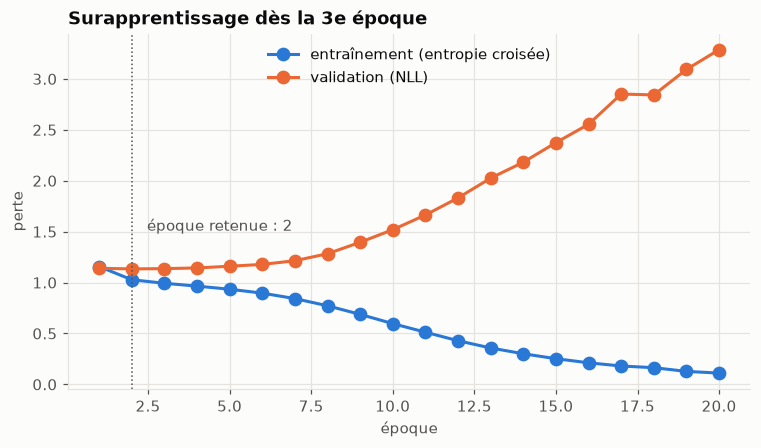

In [5]:
h = pd.DataFrame(mlp.history)
best = h.loc[h.val_nll.idxmin()]
fig, ax = plt.subplots()
ax.plot(h.epoch, h.train_ce, marker="o", label="entraînement (entropie croisée)")
ax.plot(h.epoch, h.val_nll, marker="o", label="validation (NLL)")
ax.axvline(best.epoch, color="#52514e", linestyle=":", linewidth=1)
ax.annotate(f"époque retenue : {int(best.epoch)}", (best.epoch, best.val_nll), xytext=(10, 25),
            textcoords="offset points", color="#52514e")
ax.set_xlabel("époque"); ax.set_ylabel("perte")
ax.set_title("Surapprentissage dès la 3e époque")
ax.legend()
plt.show()

Le réseau mémorise l'entraînement dès la 3e époque. Un weight decay plus fort ou un réseau plus petit ne déplacent pas le plafond de validation (~0,52) : la limite vient des étiquettes.

In [6]:
strip = lambda m: {k.replace("test_", ""): v for k, v in m.items() if not k.startswith("ood_")}
pd.DataFrame({"toujours P3 (a priori)": naive, "régression logistique": strip(logreg),
              "MLP": strip(mlp.metrics)}).round(3)

,toujours P3 (a priori),régression logistique,MLP
accuracy,0.394,0.459,0.469
macro_f1,0.141,0.400,0.401
nll,1.381,1.289,1.229
brier,0.741,0.687,0.659
ece,0.060,0.096,0.045
spearman_urgency,-0.023,0.292,0.302
p1_recall_top10,0.113,0.237,0.233


## 5. Calibration et erreurs

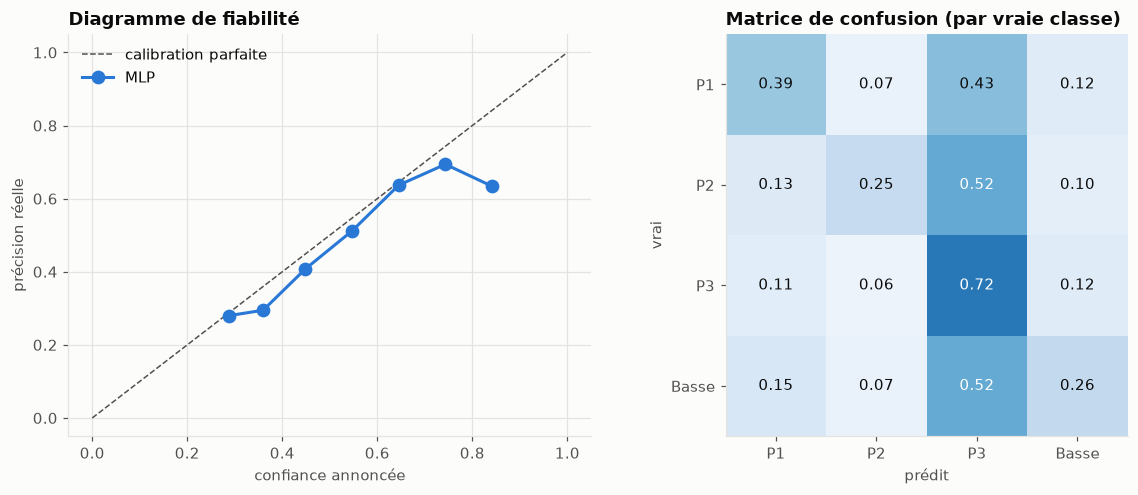

In [7]:
from sklearn.metrics import confusion_matrix
from jem_prioriser.train import predict

p_mlp, _ = predict(mlp.prioriser.model, data.x_test)

def reliability(ax, probs, y, label, color, n_bins=10):
    conf, correct = probs.max(1), (probs.argmax(1) == y)
    idx = np.clip(np.digitize(conf, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)
    keep = [b for b in range(n_bins) if (idx == b).sum() >= 20]
    ax.plot([conf[idx == b].mean() for b in keep], [correct[idx == b].mean() for b in keep],
            marker="o", label=label, color=color)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#52514e", linewidth=1, label="calibration parfaite")
reliability(axes[0], p_mlp, y_test, "MLP", MODEL_COLORS["MLP (baseline)"])
axes[0].set_xlabel("confiance annoncée"); axes[0].set_ylabel("précision réelle")
axes[0].set_title("Diagramme de fiabilité"); axes[0].legend()

cm = confusion_matrix(y_test, p_mlp.argmax(1), normalize="true")
axes[1].imshow(cm, cmap="Blues", vmin=0, vmax=1); axes[1].grid(False)
axes[1].set_xticks(range(4), CLASSES); axes[1].set_yticks(range(4), CLASSES)
axes[1].set_xlabel("prédit"); axes[1].set_ylabel("vrai")
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "#0b0b0b")
axes[1].set_title("Matrice de confusion (par vraie classe)")
plt.tight_layout()
plt.show()

- Calibration correcte jusqu'à ~65 % de confiance, sur-confiance au-delà (84 % annoncés pour 63 % de réussite), sur peu de bugs.
- Les erreurs sont dominées par un **repli vers la classe majoritaire P3**, qui reçoit 43 à 52 % des P1, P2 et Basse. Seuls 39 % des P1 et un quart des P2 et des Basse sont reconnus : la classe prédite seule est peu exploitable, d'où le **score d'urgence** continu, qui ordonne la file sans forcer une décision.

## 6. Limite : confiance face à des bugs inhabituels

Les ~12 500 bugs créés par des bots, exclus de l'entraînement, servent de jeu « hors distribution » naturel.

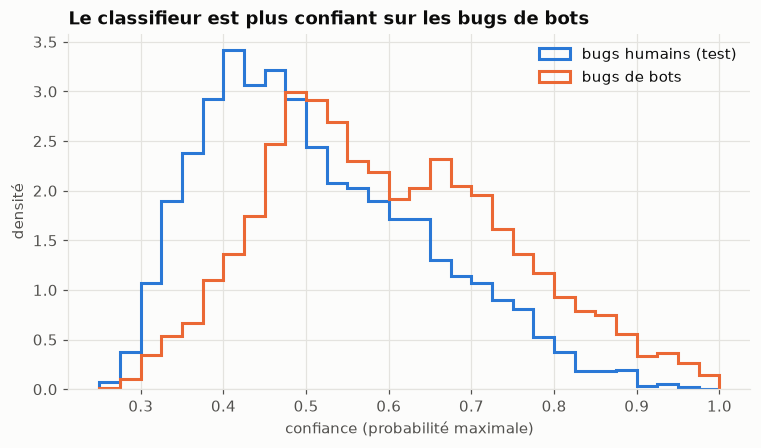

confiance moyenne : humains 0.51 | bots 0.60
AUROC de détection des bots par 1 - confiance (test 2026) : 0.35


In [8]:
p_bots, _ = predict(mlp.prioriser.model, data.x_bots)
fig, ax = plt.subplots()
bins = np.linspace(0.25, 1, 31)
ax.hist(p_mlp.max(1), bins=bins, density=True, histtype="step", linewidth=2, label="bugs humains (test)", color=HUMAN_BOT_COLORS["humains"])
ax.hist(p_bots.max(1), bins=bins, density=True, histtype="step", linewidth=2, label="bugs de bots", color=HUMAN_BOT_COLORS["bots"])
ax.set_xlabel("confiance (probabilité maximale)"); ax.set_ylabel("densité")
ax.set_title("Le classifieur est plus confiant sur les bugs de bots")
ax.legend()
plt.show()
print(f"confiance moyenne : humains {p_mlp.max(1).mean():.2f} | bots {p_bots.max(1).mean():.2f}")
print(f"AUROC de détection des bots par 1 - confiance (test 2026) : {mlp.metrics['ood_auroc_maxprob']:.2f}")

Un classifieur n'apprend que p(y | x) : face à des textes stéréotypés et étrangers, il extrapole avec **plus** d'assurance. Sa confiance ne peut pas servir à signaler un bug atypique. C'est le point de départ du JEM (notebook 03), qui apprend aussi p(x).